In [66]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.pyplot import fill_between

# CLASE 09
## Carlos Santiago Nava Pulido
SIMULACIÓN DE CAMINATAS MEDIANTE MONTECARLO

In [67]:
np.random.seed(42)
def price_montecarlos(S0, K, T, r, sigma, num_simulations, num_steps, option_type='call'):

    dt = T / num_steps
    drift = (r - 0.5 * sigma**2) * dt
    diffusion = sigma * np.sqrt(dt)
    simulated_prices = np.zeros(num_simulations)

    Z = np.random.normal(0, 1, (num_simulations, num_steps))
    log_returns = drift + diffusion * Z

    S_t = S0 * np.exp(sum(log_returns))
    price_path = S0 * np.exp(np.cumsum(log_returns,axis=0))
    simulated_prices = price_path[-1]

    # Calcular los payoffs para cada precio final simulado
    if option_type == 'call':
        payoffs = np.maximum(0, simulated_prices - K)
    elif option_type == 'put':
        payoffs = np.maximum(0, K - simulated_prices)
    else:
        raise ValueError("option_type debe ser 'call' o 'put'")

    # El precio de la opción es el valor presente esperado de los payoffs
    option_price = np.exp(-r * T) * np.mean(payoffs)

    return  price_path

In [68]:
paths = price_montecarlos(100,110,1,.05,.20,252, 1000, 'call')


In [69]:
#intervalo de conianza
path_sup = np.percentile(paths, 97.5, axis=1)
path_inf = np.percentile(paths, 2.5, axis=1)
mean_movil = np.mean(paths, axis=1)

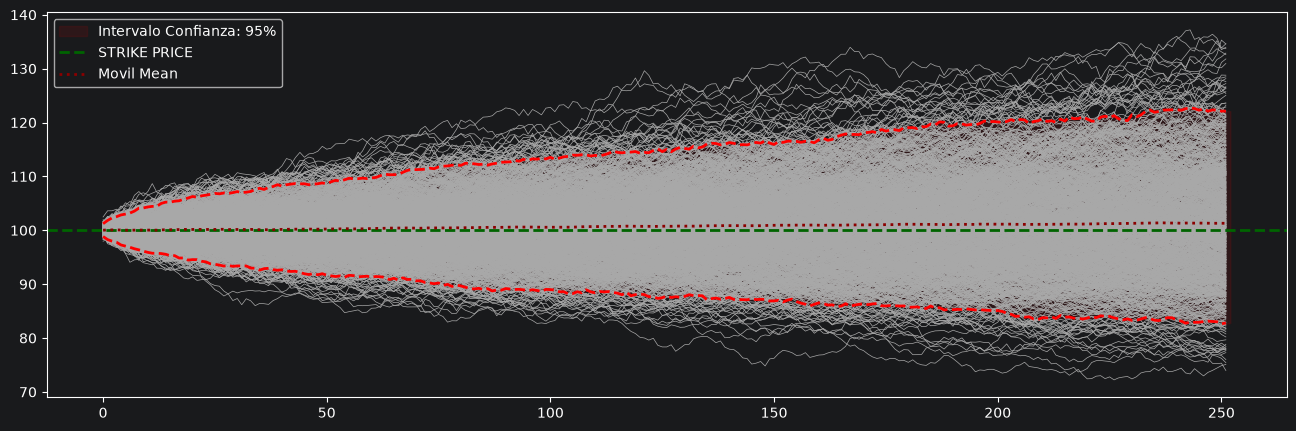

In [70]:

plt.figure(figsize=(16,5))
plt.fill_between( x = np.linspace(0,252, 252), y1 = path_sup, y2=path_inf , color='red', alpha=.09, label='Intervalo Confianza: 95%')

plt.plot(paths, linewidth=.5, color='darkgray')
plt.plot(path_sup, color='red', linestyle='dashed', linewidth=2)
plt.plot(path_inf, color='red', linestyle='dashed', linewidth=2)
plt.axhline(y=100, color='darkgreen', linestyle='dashed', linewidth=2, label='STRIKE PRICE')
plt.plot(mean_movil, color='darkred', linewidth=2, linestyle='dotted', label='Movil Mean')
plt.legend(loc='upper left')

plt.show()

# ANALISIS DE PAYOFFS

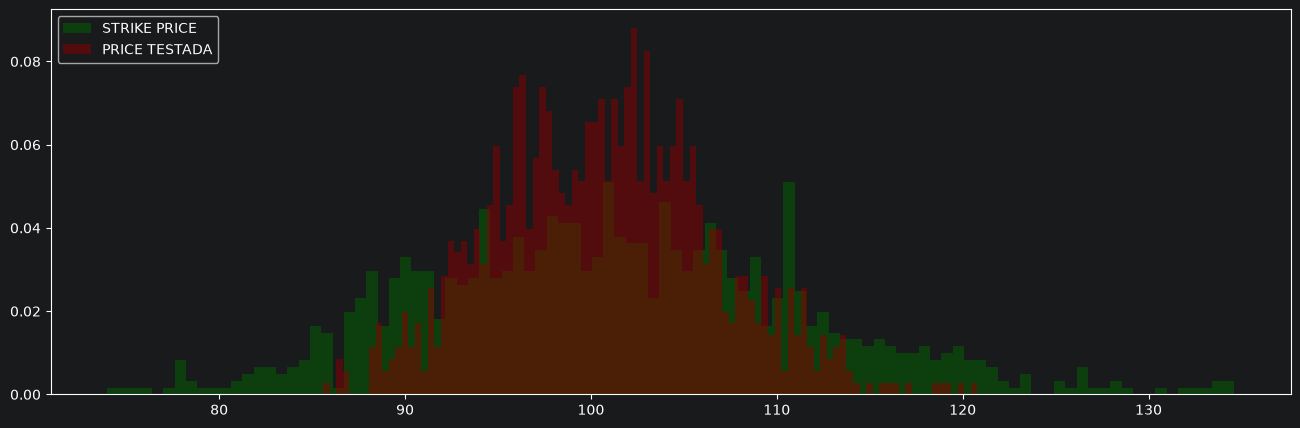

In [83]:
S = paths[-1,:]
S_testada = np.mean(paths[1:,:], axis=0)
plt.figure(figsize=(16,5))
plt.hist(S, bins=100, alpha=0.5, color='darkgreen', label='STRIKE PRICE', density=True)
plt.hist(S_testada, bins=100, alpha=0.5, color='darkred', label='PRICE TESTADA', density=True)
plt.legend(loc='upper left')
plt.show()

In [84]:
S.mean()

np.float64(101.29116564877954)

In [85]:

payoffs_call = np.exp(-.05)*np.maximum(0,S-110)
payoffs_call_mean = np.mean(payoffs_call)
print(payoffs_call_mean)


payoff_call_asiatico = np.exp(-.05)*np.maximum(0, S_testada-110)
payoff_call_asiatico_mean = np.mean(payoff_call_asiatico)
payoff_call_asiatico_mean


1.1651705894305886


np.float64(0.17027833523651817)

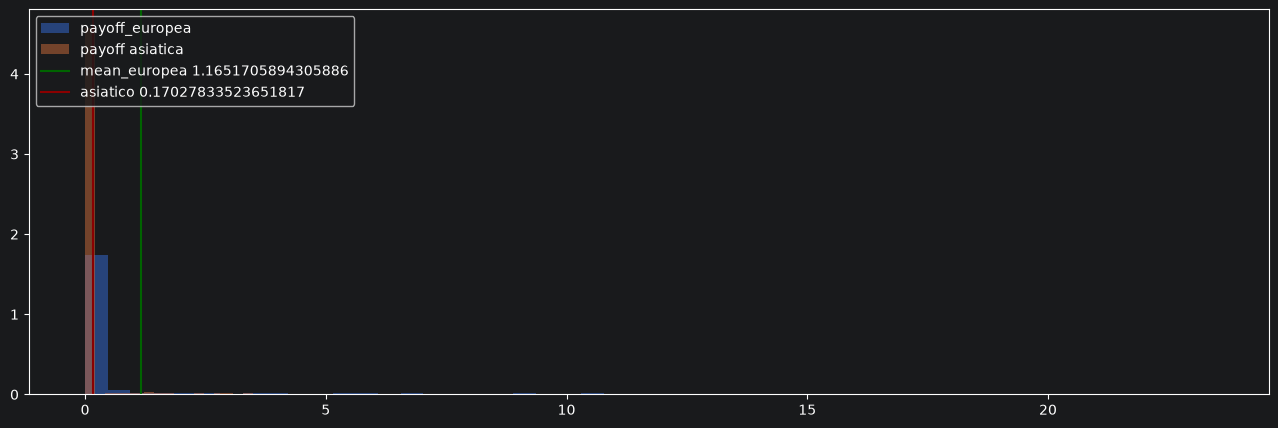

In [86]:
plt.figure(figsize=(16,5))
plt.hist(payoffs_call, density=True, bins=50, alpha=0.5 , label = 'payoff_europea')
plt.hist(payoff_call_asiatico, density=True, bins=50, alpha=0.5, label='payoff asiatica')

plt.axvline(payoffs_call_mean, color='darkgreen', label=f'mean_europea {payoffs_call_mean}')
plt.axvline(payoff_call_asiatico_mean, color='darkred', label=f'asiatico {payoff_call_asiatico_mean}')
plt.legend(loc='upper left')
plt.show()
